[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/anita-agasaveeran/Assignment4/blob/main/01_CRISP-DM_Wine_Value/notebooks/CRISP_DM_Wine_Value.ipynb)

# The $20 Bottle That Drinks Like $60: Finding Value Wines with CRISP-DM
**CMPE 255 · Assignment 4 · Project 1 of 3**

This notebook follows all six phases of CRISP-DM 1.0 (Chapman et al., 2000) and every generic task in each phase, on about 120,000 real WineEnthusiast reviews. Each task ends with the outputs the CRISP-DM user guide lists for it.

| Phase | Tasks |
|---|---|
| 1. Business Understanding | Determine business objectives · Assess situation · Determine data mining goals · Produce project plan |
| 2. Data Understanding | Collect initial data · Describe data · Explore data · Verify data quality |
| 3. Data Preparation | Select · Clean · Construct · Integrate · Format data |
| 4. Modeling | Select modeling technique · Generate test design · Build model · Assess model |
| 5. Evaluation | Evaluate results · Review process · Determine next steps |
| 6. Deployment | Plan deployment · Plan monitoring & maintenance · Produce final report · Review project |

Supporting code lives in `src/winevalue/`. The written report is `reports/final_report.md`, and critic reviews for each phase are in `critiques/`.

*Data: [Wine Reviews](https://www.kaggle.com/datasets/zynicide/wine-reviews) by Zack Thoutt, scraped from WineEnthusiast in June 2017, CC BY-NC-SA 4.0. This notebook and its outputs are shared under the same licence.*

## 0. Setup

In [1]:
# Works in Google Colab and locally. In Colab: clone the repo and install requirements.
import os, subprocess, sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/anita-agasaveeran/Assignment4.git"

if IN_COLAB:
    if not Path("/content/Assignment4").exists():
        subprocess.run(["git", "clone", "-q", REPO_URL, "/content/Assignment4"], check=True)
    PROJECT_DIR = Path("/content/Assignment4/01_CRISP-DM_Wine_Value")
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    "/content/Assignment4/requirements.txt"], check=True)
else:
    PROJECT_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

sys.path.insert(0, str(PROJECT_DIR / "src"))
os.chdir(PROJECT_DIR)
print("Project dir:", PROJECT_DIR)

Project dir: /Users/anitaagasaveeran/Desktop/MSSE_Fall2026/CMPE255/Assignment4/01_CRISP-DM_Wine_Value


In [2]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from winevalue import config
from winevalue.data import load_raw, extract_vintage

warnings.filterwarnings("ignore", category=FutureWarning)
np.random.seed(config.SEED)
pd.set_option("display.max_columns", 60)
pd.set_option("display.max_colwidth", 90)
sns.set_theme(style="whitegrid")
config.FIGURES_DIR.mkdir(parents=True, exist_ok=True)
print(f"python {sys.version.split()[0]} | pandas {pd.__version__} | sklearn {sklearn.__version__}")

python 3.12.14 | pandas 3.1.0 | sklearn 1.9.1


---
# Phase 1 · Business Understanding

> **Revision 3** (+ round-3 polish), after critic rounds 1 (7/10), 2 (8/10) and 3 (9/10, no major issues); see `critiques/phase1_business_understanding_round*.md`.
> - **Round 2 changes:** targets re-set so **every** development fold passes them, with uncertainty conditions; a pilot gate measured *relative* to note-blind rules; simple rules and RNG streams frozen in `src/`; a broader masking list; pre-registered insight hypotheses.
> - **Round 1 changes:** simulated buying cycles; a fixed simple-rule set; the region confound measured; development-only score statistics.

### 1.1 Determine business objectives

**CRISP-DM outputs:** Background · Business objectives · Business success criteria

#### Background
Critic scores sell wine. A "90 points" tag is one of the strongest quality signals a shopper has. But most wines a retailer considers have **no critic score yet**: new vintages, small producers, new imports. What the retailer usually has is a **tasting note** from the importer, the producer or its own staff, plus basic facts (origin, grape, vintage, price).

This project imagines a **hypothetical stakeholder**: the buying team of an online wine retailer. No company was interviewed, so parameters are explicit assumptions (§1.2). The team wants a *"Great Value: 90+ points for $25 or less"* collection. Each buying cycle it receives about **1,000 unscored ≤ $25 candidates** (A7) and can sample about **100** (A4).

The data is 129,971 WineEnthusiast reviews scraped in June 2017. Counts come first. Score statistics come only after the evaluation design is fixed, so they can exclude the lockbox.

In [3]:
# What is in the data? Counts only (no scores yet: the lockbox is defined in the next cell)
raw = load_raw()
df = raw.drop_duplicates().copy()          # provisional for sizing; Phase 3 formalises de-duplication
df["vintage"] = extract_vintage(df["title"])
repeat_titles = df["title"].value_counts()
overview = pd.Series({
    "raw rows": len(raw),
    "exact duplicate rows": raw.duplicated().sum(),
    "unique reviews": len(df),
    "repeat reviews of an already-reviewed title": int((repeat_titles - 1).clip(lower=0).sum()),
    "titles reviewed more than once": int((repeat_titles > 1).sum()),
    "countries": df["country"].nunique(),
    "grape varieties": df["variety"].nunique(),
    "wineries": df["winery"].nunique(),
    "named critics": df["taster_name"].nunique(),
    "reviews with no critic name": df["taster_name"].isna().sum(),
    "reviews with no price": df["price"].isna().sum(),
})
display(overview.to_frame("count"))

,count
raw rows,129971
exact duplicate rows,9983
unique reviews,119988
repeat reviews of an already-reviewed title,1148
titles reviewed more than once,934
countries,43
grape varieties,707
wineries,16757
named critics,19
reviews with no critic name,24917


#### Evaluation design (fixed now so no later phase can tune on the test data)
**What a buyer would face:** notes from writers the model has never seen. So whole critics are held out:
- **Critic folds.** The 19 named critics are dealt into 5 folds with balanced review counts.
- **Lockbox.** One fold with ≥ 3 critics is sealed as the **lockbox**, chosen with the project seed. Its *scores* aren't examined until Phase 5.
- **Development.** The other 4 folds are used for cross-validation.
- **Anonymous reviews** are used for training only.

Critics specialise by region, so holding out a critic also removes much of the training data for their regions. The coverage columns measure this using categorical columns only, which is allowed for the lockbox.

In [4]:
# Evaluation design, fixed now: critic-grouped folds, with one lockbox fold sealed until Phase 5
from winevalue.splits import critic_folds, assign_folds

mapping, LOCKBOX = critic_folds(df["taster_name"])
df["fold"] = assign_folds(df)
role = lambda f: "training only (anonymous)" if f == -1 else ("LOCKBOX (Phase 5 only)" if f == LOCKBOX else "cross-validation")

# Coverage: how much of each fold's wine "territory" the rest of the data still covers.
# Uses only categorical columns (no scores), so it's allowed for the lockbox too.
rows = []
for f in sorted(df["fold"].unique()):
    te = df[df["fold"] == f]
    tr = df[(df["fold"] != f) & (df["fold"] != LOCKBOX)] if f != LOCKBOX else df[df["fold"] != LOCKBOX]
    vc_counts = tr.groupby(["variety", "country"]).size()
    vc_key = pd.MultiIndex.from_frame(te[["variety", "country"]])
    rows.append({
        "fold": f, "role": role(f), "reviews": len(te),
        "critics": ", ".join(sorted(te["taster_name"].fillna("(anonymous)").unique())),
        "top countries": ", ".join(f"{c} {s:.0%}" for c, s in te["country"].value_counts(normalize=True).head(3).items()),
        "variety×country seen ≥20× in training": vc_counts.reindex(vc_key).fillna(0).ge(20).mean() if f != -1 else np.nan,
        "winery seen in training": te["winery"].isin(set(tr["winery"])).mean() if f != -1 else np.nan,
    })
fold_table = pd.DataFrame(rows).set_index("fold")
display(fold_table)

# From here on, Phases 1-4 never look at lockbox scores.
dev = df[df["fold"] != LOCKBOX].copy()
print(f"Development data: {len(dev):,} reviews; lockbox sealed: {(df['fold'] == LOCKBOX).sum():,} reviews")

,role,reviews,critics,top countries,variety×country seen ≥20× in training,winery seen in training
fold,,,,,,
-1,training only (anonymous),24917,(anonymous),"US 64%, Italy 32%, Australia 1%",NaN,NaN
0,cross-validation,23560,Roger Voss,"France 73%, Portugal 22%, Austria 5%",0.570586,0.105645
1,cross-validation,17812,"Jim Gordon, Michael Schachner","Spain 34%, Chile 23%, US 22%",0.292331,0.303447
2,LOCKBOX (Phase 5 only),17884,"Anne Krebiehl MW, Jeff Jenssen, Kerin O’Keefe, Sean P. Sullivan","Italy 54%, US 25%, Austria 11%",0.900973,0.730597
3,cross-validation,17810,"Anna Lee C. Iijima, Carrie Dykes, Christina Pickard, Fiona Adams, Joe Czerwinski, Paul...","US 63%, Germany 11%, Australia 11%",0.872656,0.318585
4,cross-validation,18005,"Alexander Peartree, Lauren Buzzeo, Matt Kettmann, Mike DeSimone, Susan Kostrzewa, Virg...","US 84%, South Africa 7%, France 3%",0.850708,0.705304


Development data: 102,104 reviews; lockbox sealed: 17,884 reviews


In [5]:
# Lockbox composition for per-critic reporting (counts only; no scores)
lb = df[df["fold"] == LOCKBOX]
lb_pool = lb[lb["price"] <= config.VALUE_MAX_PRICE]
display(lb_pool["taster_name"].value_counts().rename("≤$25 candidates").to_frame()
        .assign(share=lambda t: t["≤$25 candidates"] / t["≤$25 candidates"].sum()).round(3))

,≤$25 candidates,share
taster_name,,
Kerin O’Keefe,3697,0.504
Sean P. Sullivan,1757,0.240
Anne Krebiehl MW,1544,0.211
Jeff Jenssen,336,0.046


**What the lockbox tests:** new writers, in a mix of regions.
- Italy is 54% of the lockbox, but anonymous training notes still cover Italy.
- Lockbox coverage (90% variety × country, 73% winery) is better than in development folds 0 and 1, so it isn't the hardest fold. The closest development fold is **fold 3** (87% coverage, several critics, US-heavy), and every target below is checked against fold 3.
- **One critic dominates the lockbox's ≤ $25 pool:** Kerin O'Keefe has 50% of it, and Jeff Jenssen only 336 wines. Per-critic results are therefore reported as precision in the top 10% of each critic's pool, and Jenssen's are marked low-confidence.

,reviews,median_price,p90_price
points,,,
80-84,11674,15.0,32.0
85-87,31369,18.0,39.0
88-90,32464,26.0,55.0
91-93,21611,44.0,85.0
94-100,4986,74.0,200.0


Score: mean 88.3, SD 3.2. Corr(points, log price) = 0.63
Wines at or under $25: 51.8% of priced reviews; of those, 15.0% score 90+ ('value wines')


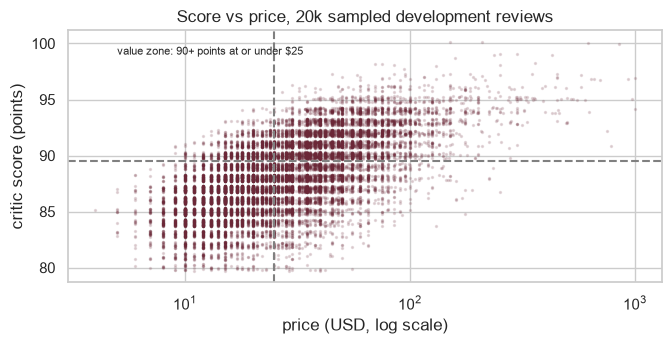

In [6]:
# Price vs score and how rare value wines are (development data only)
bands = pd.cut(dev["points"], [79, 84, 87, 90, 93, 100], labels=["80-84", "85-87", "88-90", "91-93", "94-100"])
display(dev.groupby(bands, observed=True).agg(reviews=("points", "size"), median_price=("price", "median"),
                                             p90_price=("price", lambda s: s.quantile(0.9))))
priced = dev[dev["price"].notna()]
under_cap = priced["price"] <= config.VALUE_MAX_PRICE
is_value = under_cap & (priced["points"] >= config.VALUE_MIN_POINTS)
print(f"Score: mean {dev['points'].mean():.1f}, SD {dev['points'].std():.1f}. "
      f"Corr(points, log price) = {np.corrcoef(priced['points'], np.log(priced['price']))[0, 1]:.2f}")
print(f"Wines at or under ${config.VALUE_MAX_PRICE:.0f}: {under_cap.mean():.1%} of priced reviews; "
      f"of those, {is_value[under_cap].mean():.1%} score {config.VALUE_MIN_POINTS}+ ('value wines')")

fig, ax = plt.subplots(figsize=(7, 3.6))
sample = priced.sample(20_000, random_state=config.SEED)
ax.scatter(sample["price"], sample["points"] + np.random.default_rng(0).uniform(-0.3, 0.3, len(sample)), s=2, alpha=0.15, color="#6b2737")
ax.set_xscale("log"); ax.axvline(config.VALUE_MAX_PRICE, ls="--", c="grey"); ax.axhline(config.VALUE_MIN_POINTS - 0.5, ls="--", c="grey")
ax.text(5, 99, "value zone: 90+ points at or under $25", fontsize=8)
ax.set(xlabel="price (USD, log scale)", ylabel="critic score (points)", title="Score vs price, 20k sampled development reviews")
plt.tight_layout(); plt.savefig(config.FIGURES_DIR / "p1_score_vs_price.png", dpi=150); plt.show()

**What this shows (development data):**
- Price predicts quality only partly (correlation 0.63 with log price). Median prices go from $26 at 88–90 points to $74 at 94+, with a long tail of cheap wines in every band.
- About half of priced wines cost ≤ $25, and 15% of those score 90+. In the critic-fold candidate pools used for the simulations the rate is **17.6%**. (The 15% figure also includes anonymous reviews.)
- So a team sampling 100 of 1,000 candidates at random would find about **18 value wines**.

#### Business objectives
- **BO1, value shortlist:** rank each cycle's ~1,000 unscored ≤ $25 candidates so the ~100 samples contain as many 90+ wines as possible.
- **BO2, internal score estimate:** an *estimated score band* (e.g. "est. 88–91") for buyers' planning until a real review arrives. **Internal only:** never shown to customers as WineEnthusiast points (R10).
- **BO3, shelf navigation:** flavour profiles and descriptor–grape links for collection pages.
- **BO4, catalogue quality:** detect duplicate and near-duplicate listings; "similar wines".
- **BO5, critic calibration and buyer insights:** quantify how much a score depends on who tasted the wine, and which wine attributes go with value.

Out of scope: price setting, demand forecasting, personalised recommendations (no customer data).

#### Business success criteria (pre-registered; thresholds in `config.py`)
- Measured **once**, in Phase 5, on the lockbox critics. Simple rules are scored on the same data.
- **Pass rule:** the point estimate meets the target **and** the stated lower bound holds.
- **Lower bounds** are one-sided 90%, from 500 bootstrap resamples of **wineries** (wines from the same producer move together).
- Every target below is met by **every** development fold of the untuned feasibility models (see the per-fold table in 1.2).

| ID | Criterion | Target | Lower-bound condition | Weakest development fold |
|---|---|---|---|---|
| BSC1 | **Shortlist.** Expected precision@100 of the DM2 ranker over 200 simulated cycles of 1,000 ≤ $25 candidates | ≥ 0.55 **and** ≥ 1.4× the best rule in the frozen **simple-rule set** (`winevalue.rules`: price, winery track record, province track record, variety × country, winery then price; random ties), as measured on the lockbox | Top-10% lift vs that rule ≥ 1.2× | P@100 0.61; lift 1.56×; lift lower bound 1.43× |
| BSC2 | **Internal score band.** Share of ≤ $25 candidates whose price-free estimate is within ±2 points | ≥ 0.60 and ≥ +5 pp over variety × country | Gain lower bound > 0 | 0.63; +7.3 pp (lower bound +6.0) |
| BSC3 | **Navigation.** Flavour profiles | 6–15 profiles, each ≥ 1% of wines. Two independent reviewer agents (**not** the analyst), each blind to the other, can each name ≥ 80% of profiles from their top terms with confidence ≥ 3/5 | Top-10-term Jaccard ≥ 0.5 between profiles fitted on two halves of the development data | – (Phase 4) |
| BSC4 | **Usability.** One screen. Inputs: note, country, grape, vintage, price. Outputs: est. score band, P(90+), value verdict, flavour profile, 5 similar wines | All shown in the recorded demo, < 3 s per query | – | – |
| BSC5 | **Buyer insights.** Pre-registered hypotheses H1–H6 (`config.HYPOTHESES`) | **≥ 4 of 6** replicate, **including H5 or H6**: stated direction and condition met in **both** development and lockbox data | As stated per hypothesis | – (Phase 4/5) |

**Pre-registered hypotheses (BSC5):**
- *Sanity checks (strong in development data):*
  - **H1:** longer notes go with higher scores (LB > 0).
  - **H2:** within a variety × country group, pricier wines score higher (LB > 0).
  - **H3:** a named designation goes with higher scores (same variety × country; LB > 0).
- **H4:** critics differ. The SD of critic effects (vs a training-fitted variety × country expectation) exceeds 0.5 points, **LB > 0.5**. *Limitation:* the lockbox has only 4 critics.
- *Actionable:*
  - **H5:** among ≤ $25 wines, whites are more often value wines than reds (LB > 0). The colour map is frozen in Phase 3, before any lockbox use.
  - **H6:** among ≤ $25 wines, a strong winery track record (shrunk mean ≥ 89, shrink = 20) goes with a higher value-wine rate (LB > 0).

**Necessary, not sufficient.** These criteria use *critic* notes, but the real use is on importer, producer or staff notes (A1). Deployment therefore also needs a **pilot gate** on **≥ 400 ≤ $25 retailer notes** for wines that later receive a critic score. On those same pilot wines, it must beat the note-blind rules:
- ±2 accuracy ≥ +5 pp over variety × country, with a lower bound > 0;
- the ranker's top-20% precision for 90+ wines ≥ 1.3× the **best frozen simple rule**, with a lower bound > 1.0.

400 wines give about 80% power at fold-3-like effects; 100 would pass a good model only 39–67% of the time. (`config.PILOT_*`)

### 1.2 Assess situation

**CRISP-DM outputs:** Inventory of resources · Requirements, assumptions & constraints · Risks & contingencies · Terminology · Costs & benefits

#### Inventory of resources
| Type | Resource |
|---|---|
| Data | Wine Reviews (Kaggle, Zack Thoutt): 129,971 WineEnthusiast reviews, scraped June 2017, CC BY-NC-SA 4.0. One table; no sales, inventory or customer data |
| People | One analyst (the author). **The stakeholder is hypothetical**, so business parameters (A1–A7) are explicit assumptions with sensitivity checks. No sommelier or domain expert available. Reviewers: course instructor + an independent critic; independent reviewer agents for BSC3 |
| Compute / software | Laptop + Google Colab; Python 3.12, pandas, scikit-learn, LightGBM, mlxtend, datasketch, statsmodels, Streamlit (all open source) |

#### Requirements
- **R-1, prediction timing:** when a buyer considers a wine, **before any critic review exists**. Available then: note, country/province/region, grape, winery and its *past* scores, vintage, price.
- **R-2, inputs by use:**
  - The **score estimate** (BO2) and **value verdict** exclude `price`, so "quality vs price" isn't circular.
  - The **shortlist ranker** (BO1/DM2) may use price: it's known at decision time and is itself a benchmark rule.
  - Neither may use `taster_name` / `taster_twitter_handle`.
- **R-3, honest test:**
  - The lockbox is scored once.
  - Exact duplicates are removed.
  - Test reviews whose wine title also appears in training are dropped (124 of the 934 repeat titles span folds).
  - Anonymous notes that a style classifier attributes to a lockbox critic with p > 0.5 are dropped from training (859 rows; see the check below).
- **R-4, reproducibility:**
  - Fixed seeds.
  - Cycles and tie-breaks use separate RNG streams, so every rule is scored on identical cycles.
  - The simple-rule set and the masking list are frozen in `src/`.
  - The notebook runs top to bottom in Colab and is saved with outputs.
- **R-5, licence:** derived outputs are shared under CC BY-NC-SA 4.0 with attribution.

#### Assumptions
| # | Assumption | Testable? | Handling |
|---|---|---|---|
| A1 | Retailer notes carry similar descriptive signal to critic notes | **Not with this data.** Leave-critic-out tests new *critics*, not new *kinds* of writer (producers have an incentive to praise) | Masking proxy (DM1b) now; **relative pilot gate** before deployment |
| A2 | 90+ points is a meaningful value bar | No | Also reported at 88+ / 92+ |
| A3 | 2017 prices still rank wines sensibly relative to each other | No | Ranking use only; cap also tested at $20 / $30 |
| A4 | ~100 samples per cycle | No | Also k = 50 / 200 |
| A5 | ~$25 per sample (bottle + buyer time); ~2 analyst-hours per cycle to re-score | No | Illustrative economics |
| A6 | Scores are honest; whether tastings were blind is unknown | No | Critic calibration descriptive |
| A7 | **~1,000 unscored ≤ $25 candidates per cycle** (importer and distributor catalogues for a mid-size online retailer) | No | Sensitivity at 500 / 2,000 |

#### Constraints
One static 2017 snapshot, no review dates. Only 80+ wines are published. No stakeholder interviews. One analyst and an academic timeline (§1.4).

**Anonymous-review check (R-3, R8).** Could some anonymous training notes be written by lockbox critics? A style classifier uses note *text* and critic names only, no scores. The threshold is chosen from its held-out accuracy:

In [7]:
# Could some anonymous training reviews be written by lockbox critics? A writing-style check.
# Uses note TEXT and critic names only (no scores), so the lockbox seal on scores is kept.
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.model_selection import train_test_split
named_all = df[df["taster_name"].notna()]
tr_txt, te_txt = train_test_split(named_all, test_size=0.2, random_state=config.SEED, stratify=named_all["taster_name"])
vec = TfidfVectorizer(min_df=3, ngram_range=(1, 2), max_features=100_000, sublinear_tf=True).fit(tr_txt["description"])
clf = SGDClassifier(loss="log_loss", alpha=2e-6, max_iter=30, random_state=config.SEED).fit(vec.transform(tr_txt["description"]), tr_txt["taster_name"])
held = clf.predict_proba(vec.transform(te_txt["description"]))
held_ok = clf.classes_[held.argmax(1)] == te_txt["taster_name"].to_numpy()
anon = df[df["taster_name"].isna()]
proba = clf.predict_proba(vec.transform(anon["description"]))
top_p, top_critic = proba.max(axis=1), clf.classes_[proba.argmax(axis=1)]
lockbox_critics = [c for c, f in mapping.items() if f == LOCKBOX]
sens = pd.DataFrame([{"threshold": t,
                      "accuracy on held-out named notes above threshold": held_ok[held.max(1) > t].mean(),
                      "anonymous notes above threshold": int((top_p > t).sum()),
                      "of which attributed to a lockbox critic": int(((top_p > t) & np.isin(top_critic, lockbox_critics)).sum())}
                     for t in (0.5, 0.7, 0.9)]).set_index("threshold")
display(sens.round(3))
ANON_LOCKBOX_LIKE = anon.index[(top_p > config.ATTRIBUTION_THRESHOLD) & np.isin(top_critic, lockbox_critics)]
print(f"Overall held-out accuracy {held_ok.mean():.1%}. Rows dropped from training in Phase 3 (p > {config.ATTRIBUTION_THRESHOLD}): "
      f"{len(ANON_LOCKBOX_LIKE):,} ({len(ANON_LOCKBOX_LIKE) / len(anon):.1%} of anonymous notes)")

,accuracy on held-out named notes above threshold,anonymous notes above threshold,of which attributed to a lockbox critic
threshold,,,
0.5,0.992,11872,859
0.7,0.998,4418,329
0.9,1.000,341,29


Overall held-out accuracy 98.4%. Rows dropped from training in Phase 3 (p > 0.5): 859 (3.4% of anonymous notes)


At p > 0.5 the classifier is still **99.2%** accurate on held-out named notes. Dropping the 859 anonymous notes it assigns to lockbox critics costs only 3.4% of anonymous training data, so 0.5 is used (`config.ATTRIBUTION_THRESHOLD`).

#### Risks & contingencies
| # | Risk | Likelihood | Impact | Contingency |
|---|---|---|---|---|
| R1 | **Note-source shift** (A1) | High | High | Masking test (DM1b); relative pilot gate; BSCs "necessary, not sufficient" |
| R2 | **Region confound:** holding out critics also holds out regions (variety × country coverage 29–87% by development fold), so the variety × country baseline looks weaker than on a random split | Confirmed | Medium | Both splits reported; targets set on the critic split; per-fold and per-critic results |
| R3 | **Duplicates / repeat titles:** 9,983 dups; 1,148 repeat reviews of 934 titles; 124 titles span folds | Confirmed | High if ignored | Dups removed; test rows with a training title dropped |
| R4 | **Selection bias:** only 80+ wines are published | Confirmed | Medium | Stated limitation |
| R5 | **Stale prices**, single snapshot | Confirmed | Low–Medium | Ranking use only; cap sensitivity |
| R6 | **Critic differences** for the same variety and country | Observed (descriptive) | Medium | H4 / DM6; the lockbox mixes 4 critics |
| R7 | **Long-tail categories:** 707 grapes, 16,757 wineries | Confirmed | Medium | Rare-category grouping (Phase 3) |
| R8 | **Anonymous notes by lockbox critics** | Small | Low | 859 rows (p > 0.5) dropped from training |
| R9 | **Weak lockbox result.** Development margins are smallest for fold 3 (the fold most like the lockbox) on DM1/BSC2, and for folds 1 and 4 on BSC1 | Medium | Medium | Every target is met by every development fold; winery-clustered lower bounds; per-critic reporting |
| R10 | **Misleading or infringing display** of estimated "points" | Medium | Medium | Internal "estimated band" only, labelled |
| R11 | **One critic dominates the lockbox** (O'Keefe: 50% of the ≤ $25 pool) | Confirmed | Medium | Per-critic top-10% precision; results reported with and without O'Keefe |
| R12 | **Licence (NC-SA)** limits commercial use | Confirmed | Low (academic) | Stated in README and app |

#### Terminology
**Critic score / points:** WineEnthusiast's 80–100 rating · **Value wine:** 90+ points at ≤ $25 · **Tasting note:** the `description` · **Candidate pool / cycle:** unscored ≤ $25 wines considered in one buying round (A7) · **Shortlist:** the top k to sample · **Precision@k / top-10% precision:** share of a shortlist that are value wines · **Simple-rule set:** the frozen non-ML rankings in `winevalue.rules` · **Lift:** ranker precision ÷ best simple-rule precision · **MAE:** mean absolute error · **Within ±2:** share of estimates within 2 points · **Critic fold / lockbox:** a held-out group of critics / the fold sealed until Phase 5 · **Lower bound (LB):** one-sided 90% winery-clustered bootstrap bound · **Evaluative language:** words and phrases that state a verdict or drinking window (`config.EVALUATIVE_TERMS`, `EVALUATIVE_PATTERNS`) · **TF-IDF:** word weighting for notes · **Flavour profile:** a cluster of similar notes · **Support / confidence / lift (rules):** association-rule statistics · **MinHash LSH:** fast near-duplicate search.

#### Costs & benefits
**Feasibility check.** Development folds only; untuned models; test rows with a training title dropped. Shortlists are scored over 200 simulated cycles (cycles and ties on separate RNG streams, one tie stream per rule); lower bounds use a winery-clustered bootstrap. Training here uses all anonymous rows: the R-3 attribution filter (859 rows, none of them lockbox rows) starts in Phase 3.

In [8]:
# Feasibility on development folds (lockbox untouched). Untuned models; each critic fold held out in turn;
# test rows whose title appears in training are dropped (R-3). Uncertainty: one-sided 90%, winery-clustered bootstrap.
from winevalue.models import GroupMeanBaseline, quick_text_model, mask_terms, mask_evaluative, QUALITY_INPUTS, RANKER_INPUTS
from winevalue.metrics import mae, within, cluster_bootstrap
from winevalue.rules import SIMPLE_RULES, simple_rule_scores
from winevalue.splits import drop_titles_seen_in_training
from winevalue.value import simulate_cycles, cluster_bootstrap_lift, precision_top_frac

K, N_CAND = config.SHORTLIST_K, config.CANDIDATES_PER_CYCLE
RANKER = "DM2 ranker (text + price)"
cv_folds = sorted(f for f in dev["fold"].unique() if f >= 0)
score_rows, fold_rows, shelf_rows, pools = [], [], [], {}
for f in cv_folds:
    tr = dev[dev["fold"] != f]
    te = drop_titles_seen_in_training(dev[dev["fold"] == f], tr)
    y = te["points"].to_numpy()
    fit_pred = lambda train, test: quick_text_model().fit(train[QUALITY_INPUTS], train["points"]).predict(test[QUALITY_INPUTS])
    preds = {"global mean": np.full(len(te), tr["points"].mean()),
             "variety × country": GroupMeanBaseline().fit(tr, tr["points"]).predict(te),
             "text model": fit_pred(tr, te)}
    for label, masker in [("masked, round-1 list", lambda s: mask_terms(s, config.EVALUATIVE_TERMS_V1)),
                          ("masked, frozen list", mask_evaluative)]:
        preds[f"text model, {label}"] = fit_pred(tr.assign(description=masker(tr["description"])),
                                                 te.assign(description=masker(te["description"])))
    cand = (te["price"] <= config.VALUE_MAX_PRICE).to_numpy()
    for name, p in preds.items():
        score_rows.append({"fold": f, "predictor": name, "MAE": mae(y, p), "within ±2 (≤$25)": within(y[cand], p[cand])})

    vc, tm, wineries = preds["variety × country"], preds["text model"], te["winery"].to_numpy()
    red = cluster_bootstrap(lambda i: 1 - mae(y[i], tm[i]) / mae(y[i], vc[i]), wineries, seed=config.SEED)
    c_idx = np.flatnonzero(cand)
    gain = cluster_bootstrap(lambda i: within(y[c_idx][i], tm[c_idx][i]) - within(y[c_idx][i], vc[c_idx][i]),
                             wineries[c_idx], seed=config.SEED)

    pool = te[cand]
    is_val = (pool["points"] >= config.VALUE_MIN_POINTS).to_numpy()
    rules = simple_rule_scores(tr, pool)
    rules["text model (no price)"] = tm[cand]
    rules[RANKER] = quick_text_model(with_price=True).fit(tr[RANKER_INPUTS], tr["points"]).predict(pool[RANKER_INPUTS])
    pools[f] = (pool, is_val, rules)
    res = {n: simulate_cycles(rules, is_val, n_candidates=n, k=K, n_cycles=config.N_SIM_CYCLES, seed=config.SEED + f)
           for n in (500, N_CAND, 2000)}
    for n, r in res.items():
        shelf_rows.append({"fold": f, "candidates per cycle": n, "value base rate": is_val.mean(), **r.mean().to_dict()})
    best = max(SIMPLE_RULES, key=lambda r: res[N_CAND][r].mean())
    lift = cluster_bootstrap_lift(rules[RANKER], rules[best], is_val, pool["winery"], frac=0.1, seed=config.SEED)
    fold_rows.append({
        "fold": f, "≤$25 pool": len(pool),
        "MAE reduction vs v×c": red["estimate"], "MAE reduction 90% LB": red["lower_bound"],
        "within ±2 gain (pp)": 100 * gain["estimate"], "within ±2 gain 90% LB (pp)": 100 * gain["lower_bound"],
        "best simple rule": best, "best simple P@100": res[N_CAND][best].mean(),
        "ranker P@100": res[N_CAND][RANKER].mean(), "lift (cycles)": res[N_CAND][RANKER].mean() / res[N_CAND][best].mean(),
        "lift top-10% (bootstrap point)": lift["lift"], "lift 90% LB": lift["lower_bound"],
    })

scores = pd.DataFrame(score_rows)
score_table = scores.pivot_table(index="predictor", columns="fold", values=["MAE", "within ±2 (≤$25)"])
for m in ("MAE", "within ±2 (≤$25)"):
    score_table[(m, "mean")] = score_table[m].mean(axis=1)
display(score_table.sort_index(axis=1).round(3))
mae_by = scores.pivot(index="fold", columns="predictor", values="MAE")
masking = pd.DataFrame({
    "MAE increase, round-1 list": mae_by["text model, masked, round-1 list"] - mae_by["text model"],
    "MAE increase, frozen list": mae_by["text model, masked, frozen list"] - mae_by["text model"],
    "improvement kept, frozen list": (mae_by["variety × country"] - mae_by["text model, masked, frozen list"])
                                     / (mae_by["variety × country"] - mae_by["text model"])})
masking.loc["mean"] = masking.mean()
display(masking.round(3))
per_fold = pd.DataFrame(fold_rows).set_index("fold")
display(per_fold.round(3))
shelf = pd.DataFrame(shelf_rows)
display(shelf.groupby("candidates per cycle")[["value base rate", *SIMPLE_RULES, "text model (no price)", RANKER]].mean().T.round(3))

MAE                              \
fold                                  0      1      3      4   mean   
predictor                                                             
global mean                       2.561  2.761  2.333  2.584  2.560   
text model                        1.829  1.746  2.001  1.721  1.824   
text model, masked, frozen list   1.925  1.852  2.067  1.750  1.899   
text model, masked, round-1 list  1.886  1.791  2.059  1.740  1.869   
variety × country                 2.716  2.616  2.271  2.515  2.529   

                                 within ±2 (≤$25)                              
fold                                            0      1      3      4   mean  
predictor                                                                      
global mean                                 0.490  0.420  0.580  0.534  0.506  
text model                                  0.711  0.700  0.628  0.717  0.689  
text model, masked, frozen list             0.705  0.689  0.616  0.694  0.676  
text model, masked, round-1 list            0.711  0.690  0.614  0.705  0.680  
variety × country                           0.549  0.475  0.555  0.540  0.530

,"MAE increase, round-1 list","MAE increase, frozen list","improvement kept, frozen list"
fold,,,
0,0.058,0.096,0.892
1,0.045,0.106,0.878
3,0.058,0.066,0.756
4,0.019,0.029,0.964
mean,0.045,0.074,0.872


,≤$25 pool,MAE reduction vs v×c,MAE reduction 90% LB,within ±2 gain (pp),within ±2 gain 90% LB (pp),best simple rule,best simple P@100,ranker P@100,lift (cycles),lift top-10% (bootstrap point),lift 90% LB
fold,,,,,,,,,,,
0,10794,0.327,0.315,16.268,15.203,price (pricier first),0.418,0.662,1.581,1.625,1.496
1,12659,0.332,0.323,22.443,21.377,price (pricier first),0.340,0.608,1.789,1.788,1.696
3,9032,0.119,0.105,7.263,5.998,"winery track record, then price",0.337,0.717,2.129,2.105,1.921
4,6137,0.316,0.308,17.777,16.588,"winery track record, then price",0.395,0.618,1.563,1.557,1.426


candidates per cycle,500,1000,2000
value base rate,0.176,0.176,0.176
price (pricier first),0.340,0.363,0.371
winery track record,0.224,0.260,0.305
province track record,0.181,0.166,0.140
variety × country,0.183,0.181,0.174
"winery track record, then price",0.325,0.361,0.371
text model (no price),0.489,0.603,0.699
DM2 ranker (text + price),0.517,0.651,0.759


**Is the weak baseline an artefact of the critic split?** Compare with a random, title-grouped split of the same development data:

In [9]:
# How much of the baseline's weakness comes from the critic split itself? Same comparison on a
# random split of the development data, grouped by title so no wine is on both sides.
from sklearn.model_selection import GroupShuffleSplit
tr_i, te_i = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=config.SEED).split(dev, groups=dev["title"]))
tr, te = dev.iloc[tr_i], dev.iloc[te_i]
y = te["points"].to_numpy()
rnd = {"global mean": mae(y, np.full(len(te), tr["points"].mean())),
       "variety × country": mae(y, GroupMeanBaseline().fit(tr, tr["points"]).predict(te)),
       "text model": mae(y, quick_text_model().fit(tr[QUALITY_INPUTS], tr["points"]).predict(te[QUALITY_INPUTS]))}
crit = scores.groupby("predictor")["MAE"].mean()
display(pd.DataFrame({"random split (title-grouped)": rnd,
                      "critic split (mean of 4 folds)": crit.reindex(list(rnd))}).round(3))

,random split (title-grouped),critic split (mean of 4 folds)
global mean,2.600,2.560
variety × country,2.390,2.529
text model,1.301,1.824


**Feasibility verdict (all figures from the tables above):**
- **Score estimate.** For unseen critics, the text model cuts MAE by **12–33%** vs variety × country (mean 27%; fold 3 lowest at 12%, lower bound 10.5%). ±2 accuracy on ≤ $25 candidates is 0.63–0.72, a gain of +7.3 to +22.4 pp over variety × country.
- **Not just verdict words.** With the frozen evaluative list masked (verdict words + drinking windows), MAE rises by only **0.03–0.11 points**, and **87%** of the improvement is kept on average (76% in fold 3). The narrower round-1 list kept 91%.
- **The baseline's weakness is partly the split.** On a random title-grouped split, variety × country beats the global mean by about 8% (2.39 vs 2.60); on the critic split, by about 1%. New writers in partly new regions are genuinely harder.
- **Shortlist** (cycles of 1,000):
  - The best simple rule is *price* (folds 0–1) or *winery track record, then price* (folds 3–4), at 0.34–0.42.
  - The **DM2 ranker reaches 0.61–0.72**, a lift of 1.56–2.13× (lower bounds 1.43–1.92×).
  - Precision rises with pool size: 0.52 / 0.65 / 0.76 for 500 / 1,000 / 2,000 candidates.
- **Targets:** every pre-registered target (BSC1, BSC2, DM1, DM1b) is met by **every** development fold, including its lower-bound condition.
- *Disclosure:* one exploratory check, run before the lockbox existed, used all critics. All figures here use development data only.

In [10]:
# Sampling economics per buying cycle (A4 = 100 samples, A5 = $25/sample, A7 = 1,000 candidates). Development folds.
COST_PER_SAMPLE, ANALYST_COST, RUNNING_COST_PER_CYCLE = 25.0, 70 * 50.0, 2 * 50.0   # 2 analyst-hours to re-score each cycle
ks = list(range(10, K + 1, 2))
finds = {}   # expected value wines found among the top-k, averaged over folds and cycles
for f, (pool, is_val, rules) in pools.items():
    for k in ks:
        r = simulate_cycles({"random": np.zeros(len(pool)), "best simple": rules[per_fold.loc[f, "best simple rule"]], RANKER: rules[RANKER]},
                            is_val, n_candidates=N_CAND, k=k, n_cycles=50, seed=config.SEED + f)
        for name in r:
            finds.setdefault((name, k), []).append(k * r[name].mean())
finds = pd.Series({key: np.mean(v) for key, v in finds.items()}).unstack(0)
at100 = finds.loc[K]
econ = pd.DataFrame({"value wines found in 100 samples": at100, "precision@100": at100 / K,
                     "sampling cost per value wine": COST_PER_SAMPLE * K / at100}).loc[["random", "best simple", RANKER]]
display(econ.round(2))
need = finds.index[(finds[RANKER] >= at100["best simple"]).to_numpy()].min()
opportunity = (at100[RANKER] - at100["best simple"]) * econ.loc["best simple", "sampling cost per value wine"]
cash = (K - need) * COST_PER_SAMPLE
print(f"Opportunity value: +{at100[RANKER] - at100['best simple']:.1f} value wines per cycle ≈ ${opportunity:,.0f} at the best simple rule's cost per find")
print(f"Cash framing: the ranker matches the best rule's {at100['best simple']:.1f} finds with ≈ {need} samples instead of {K}, "
      f"saving ≈ ${cash:,.0f} per cycle; net of ${RUNNING_COST_PER_CYCLE:.0f} running cost ≈ ${cash - RUNNING_COST_PER_CYCLE:,.0f}")
print(f"Break-even on ≈ ${ANALYST_COST:,.0f} of analyst time: {ANALYST_COST / (cash - RUNNING_COST_PER_CYCLE):.1f} cycles (cash), "
      f"{ANALYST_COST / (opportunity - RUNNING_COST_PER_CYCLE):.1f} cycles (opportunity value)")

,value wines found in 100 samples,precision@100,sampling cost per value wine
random,17.13,0.17,145.94
best simple,37.16,0.37,67.27
DM2 ranker (text + price),65.41,0.65,38.22


Opportunity value: +28.2 value wines per cycle ≈ $1,900 at the best simple rule's cost per find
Cash framing: the ranker matches the best rule's 37.2 finds with ≈ 50 samples instead of 100, saving ≈ $1,250 per cycle; net of $100 running cost ≈ $1,150
Break-even on ≈ $3,500 of analyst time: 3.0 cycles (cash), 1.9 cycles (opportunity value)


In [11]:
# Do critics score differently for the same variety and country? (development data; descriptive only,
# because critics also differ in which wines they review within a variety × country)
named = dev[dev["taster_name"].notna()]
resid = named["points"] - GroupMeanBaseline().fit(dev, dev["points"]).predict(named)
critic_bias = (pd.DataFrame({"critic": named["taster_name"], "score": named["points"], "vs_expected": resid})
                 .groupby("critic").agg(reviews=("score", "size"), mean_score=("score", "mean"),
                                        mean_vs_variety_country=("vs_expected", "mean"))
                 .query("reviews >= 100").sort_values("mean_vs_variety_country"))
display(critic_bias.round(2))
print(f"Range of critic averages vs variety × country expectation: "
      f"{critic_bias['mean_vs_variety_country'].min():+.2f} to {critic_bias['mean_vs_variety_country'].max():+.2f} points")

,reviews,mean_score,mean_vs_variety_country
critic,,,
Alexander Peartree,383,85.78,-2.30
Carrie Dykes,129,86.36,-1.64
Susan Kostrzewa,1023,86.58,-1.36
Lauren Buzzeo,1700,87.69,-0.48
Anna Lee C. Iijima,4017,88.42,-0.39
Michael Schachner,14046,86.86,-0.24
Joe Czerwinski,4766,88.52,-0.03
Roger Voss,23560,88.73,0.05
Jim Gordon,3766,88.60,0.33


Range of critic averages vs variety × country expectation: -2.30 to +1.35 points


**Benefits (conditional on A4, A5, A7):**

| Framing | Per cycle | Break-even on ~$3,500 of analyst time |
|---|---|---|
| **Cash** (sampling spend the ranker saves while finding as many value wines as the best simple rule) | ≈ 50 instead of 100 samples → ≈ $1,250, ≈ $1,150 after $100 running cost | ≈ 3 cycles |
| **Opportunity value** (sampling all 100 anyway) | ≈ +28 value wines, worth ≈ $1,900 at the simple rule's cost per find | ≈ 2 cycles |

- **Revenue upside:** a fuller value collection is probably worth more, but can't be quantified without sales data, so it isn't claimed.
- **Other benefits:** internal score bands (BO2), navigation (BO3), catalogue hygiene (BO4).

**Critic differences (descriptive).** For the *same variety and country*, critics' average scores range from −2.30 to +1.35 points vs expectation. Critics also differ in which wines they review, so H4 and DM6 test this properly.

**Costs:**
- About 60–80 analyst-hours (≈ $3,500 at an assumed $50/h); open-source software; free hosting.
- About 2 analyst-hours per cycle to re-score, plus a quarterly drift check.
- A pilot on about 100 retailer notes.

### 1.3 Determine data mining goals

**CRISP-DM outputs:** Data mining goals · Data mining success criteria

| ID | Data mining goal | Technique | Success criterion (lockbox, Phase 5) | Uncertainty | Supports |
|---|---|---|---|---|---|
| DM1 | **Estimate the critic score** from note + origin + grape + vintage (no price, no critic) | Baselines vs ridge on TF-IDF, gradient boosting, optional transformer embeddings | MAE ≥ 10% below variety × country; plus BSC2 | Lower bound of the reduction > 5% | BO2 |
| DM1b | **Signal beyond verdict words** | Same model with the frozen evaluative list masked | Masked-model MAE ≤ DM1 MAE + 0.15 points (absolute, so it's stable even when DM1's reduction is small) | Point estimate | BO1, BO2 (A1 proxy) |
| DM2 | **Rank ≤ $25 candidates** | DM1 model + log price (or a direct P(90+) classifier) | = BSC1. Also reported at k = 50/200 and pools of 500/2,000 | = BSC1 | BO1 |
| DM3 | **Flavour profiles** | k-means / NMF on TF-IDF or embeddings; outlier notes checked | = BSC3. Silhouette or topic coherence reported | = BSC3 | BO3 |
| DM4 | **Descriptor ↔ grape links** | FP-Growth on descriptor sets + grape | ≥ 10 rules with lift ≥ 2 and support ≥ 0.5% in development data that keep lift ≥ 1.5 in the lockbox | Point estimate | BO3, BO5 |
| DM5 | **Near-duplicates and similar wines** | MinHash LSH on note shingles | Recall ≥ 0.9 of exact-Jaccard ≥ 0.8 pairs on a 10k sample; precision ≥ 0.9 on 100 hand-checked flagged pairs | Point estimate | BO4 |
| DM6 | **Critic calibration** | Fixed / mixed effects: score ~ wine attributes + critic | Critic effects with 95% CIs; feeds H4 / BSC5 | As BSC5 | BO5 |

**Outlier analysis** (course template) is a supporting step in Phases 2–3: price outliers (up to $3,300), odd vintages, unusually short or long notes.

### 1.4 Produce project plan

**CRISP-DM outputs:** Project plan · Initial assessment of tools & techniques

Dates assume work started 2026-11-03. `instructions.txt` gives no due date. **The assignment due date still needs confirming with the project owner**, and the dates will be adjusted to fit it.

| Phase | Planned dates | Effort | Inputs → outputs | Milestone / go-no-go |
|---|---|---|---|---|
| 1 Business Understanding | Nov 3–4 | 10% | Raw data → §1; frozen evaluation design, rules, targets, hypotheses | Critic: no major issues |
| 2 Data Understanding | Nov 4–6 | 20% | §1 → description, EDA, quality report (**development data only** for score analysis) | Quality issues logged |
| 3 Data Preparation | Nov 6–9 | 25% | §2 → cleaned table, R-3 filters, features (incl. wine colour for H5), text pipeline | Leakage audit passes |
| 4 Modeling | Nov 9–12 | 20% | §3 → DM1–DM6 on development folds | DM targets met in CV, or loop back to 3 |
| *Buffer* | Nov 13 | – | Absorbs one loop-back (Phase 4 → 3) | – |
| 5 Evaluation | Nov 14 | 10% | §4 → single lockbox run, BSC1–BSC5 | Go/no-go |
| 6 Deployment | Nov 15–17 | 15% | §5 → Value Finder app, monitoring, pilot plan, report, article, video | Final critic review |

**Fallback scope:** if time runs short, DM5 (LSH) and DM6 (critic model) shrink to a minimal demonstration. DM1, DM1b, DM2 and DM3 are protected.

**Resources:** one analyst for every phase, plus an independent critic review (≥ 2 rounds) at the end of each.

**Initial assessment of tools & techniques:**
- **scikit-learn:** TF-IDF, ridge, k-means, NMF; pipelines fit inside each fold.
- **LightGBM:** non-linear models.
- **mlxtend:** FP-Growth.
- **datasketch:** MinHash LSH.
- **statsmodels:** critic effects with CIs.
- **Streamlit:** the app.
- **IBM SPSS Modeler** (suggested in the assignment) has a CRISP-DM project view, but needs a licence, handles free text poorly and can't be shared as a runnable notebook, so the structure is followed in this notebook and report instead.

> **Critic review: Phase 1.** The revisions are logged in `critiques/phase1_business_understanding_round*.md`.
> The phase is finished when every output above is filled in and the latest critic round lists no major issues.

---
# Phase 2 · Data Understanding

### 2.1 Collect initial data

**CRISP-DM outputs:** Initial data collection report

In [12]:
# TODO: Source, licence, scrape date, checksum, files (130k-v2 vs first150k), how it was obtained.

### 2.2 Describe data

**CRISP-DM outputs:** Data description report

In [13]:
# TODO: Types, cardinalities, ranges, units; grain (one review per row); text length.

### 2.3 Explore data

**CRISP-DM outputs:** Data exploration report

In [14]:
# TODO: Scores, prices, origins, grapes, critics, vintages; words vs score; price-quality by region and grape.

### 2.4 Verify data quality

**CRISP-DM outputs:** Data quality report

In [15]:
# TODO: Duplicates and repeat titles (R3 gate), missing price/critic/region, odd vintages, price outliers, encoding issues.

> **Critic review: Phase 2.** The revisions are logged in `critiques/phase2_data_understanding_round*.md`.

---
# Phase 3 · Data Preparation

### 3.1 Select data

**CRISP-DM outputs:** Rationale for inclusion / exclusion

In [16]:
# TODO: Rows and columns per goal; leakage exclusions (price, critic) per R-2.

### 3.2 Clean data

**CRISP-DM outputs:** Data cleaning report

In [17]:
# TODO: Deduplication (fold-safe), missing values, outlier handling, text normalisation.

### 3.3 Construct data

**CRISP-DM outputs:** Derived attributes · Generated records

In [18]:
# TODO: Vintage, wine age at review, region grouping, note length, descriptor sets.

### 3.4 Integrate data

**CRISP-DM outputs:** Merged data

In [19]:
# TODO: Single table: no external sources; document why.

### 3.5 Format data

**CRISP-DM outputs:** Reformatted data · Dataset · Dataset description

In [20]:
# TODO: sklearn pipelines; save processed data.

> **Critic review: Phase 3.** The revisions are logged in `critiques/phase3_data_preparation_round*.md`.

---
# Phase 4 · Modeling

### 4.1 Select modeling technique

**CRISP-DM outputs:** Modeling technique · Modeling assumptions

In [21]:
# TODO: DM1–DM6 techniques and their assumptions.

### 4.2 Generate test design

**CRISP-DM outputs:** Test design

In [22]:
# TODO: Critic-fold CV on development folds (lockbox untouched); metrics per DM goal.

### 4.3 Build model

**CRISP-DM outputs:** Parameter settings · Models · Model descriptions

In [23]:
# TODO: Fit and tune; save artifacts.

### 4.4 Assess model

**CRISP-DM outputs:** Model assessment · Revised parameter settings

In [24]:
# TODO: CV results vs baselines; error analysis by critic, country, grape.

> **Critic review: Phase 4.** The revisions are logged in `critiques/phase4_modeling_round*.md`.

---
# Phase 5 · Evaluation

### 5.1 Evaluate results

**CRISP-DM outputs:** Assessment w.r.t. business success criteria · Approved models

In [25]:
# TODO: Single lockbox run; BSC1–BSC5.

### 5.2 Review process

**CRISP-DM outputs:** Review of process

In [26]:
# TODO: Audit all phases for leakage and missed steps.

### 5.3 Determine next steps

**CRISP-DM outputs:** List of possible actions · Decision

In [27]:
# TODO: Go/no-go with reasons.

> **Critic review: Phase 5.** The revisions are logged in `critiques/phase5_evaluation_round*.md`.

---
# Phase 6 · Deployment

### 6.1 Plan deployment

**CRISP-DM outputs:** Deployment plan

In [28]:
# TODO: Value Finder app (deployment/app.py), saved pipeline.

### 6.2 Plan monitoring & maintenance

**CRISP-DM outputs:** Monitoring & maintenance plan

In [29]:
# TODO: Drift, re-scoring, retraining triggers.

### 6.3 Produce final report

**CRISP-DM outputs:** Final report · Final presentation

In [30]:
# TODO: Report, Medium article, video script.

### 6.4 Review project

**CRISP-DM outputs:** Experience documentation

In [31]:
# TODO: Lessons learned.

> **Critic review: Phase 6.** The revisions are logged in `critiques/phase6_deployment_round*.md`.